# KIBA GIN + CNN Drug–Target Affinity Prediction

This notebook evaluates a **GIN + CNN** model on the KIBA drug–target affinity dataset.

The drug is represented as a molecular graph and encoded using a Graph Isomorphism Network (GIN).  
The protein is represented as an amino-acid sequence and encoded using a one-dimensional CNN.

Three evaluation settings are used:

- Random split
- Cold-drug split
- Cold-target split

The same model architecture and training settings are used for all three experiments so that the effect of the data split can be compared fairly.

KIBA affinity scores are used directly as the regression target; they are not converted to pKd.


The GIN drug encoder uses learnable MLP-based neighbourhood aggregation. The protein CNN and final prediction head remain the same as in the other baseline models.

## Notebook workflow

```text
Raw KIBA dataset
        │
        ▼
Load drugs, proteins and affinity matrix
        │
        ▼
Keep valid KIBA affinity scores
        │
        ├───────────────────────────────┐
        ▼                               ▼
SMILES                              Protein sequence
        │                               │
        ▼                               ▼
RDKit molecular graph              Integer encoding
        │                               │
        ▼                               ▼
GIN drug encoder                   1D CNN protein encoder
        └───────────────┬───────────────┘
                        ▼
                Combined representation
                        │
                        ▼
                 Affinity prediction
                        │
        ┌───────────────┼────────────────┐
        ▼               ▼                ▼
   Random split     Cold-drug        Cold-target
        │               │                │
        ▼               ▼                ▼
 Train / validate / test with early stopping
        │               │                │
        └───────────────┼────────────────┘
                        ▼
            MSE, RMSE, MAE, CI, Pearson
                        │
                        ▼
         Save checkpoints, predictions,
              figures and metrics
                        │
                        ▼
             Compare the three splits
```

The notebook starts from the raw KIBA files and finishes by saving a single model-level metrics table for later comparison with GCN and GAT.


In [1]:
# ============================================================
# COLAB SETUP — DRIVE + GITHUB + PERMANENT RESULTS
# ============================================================

from google.colab import drive, userdata
from pathlib import Path

import base64
import os
import shutil
import subprocess
import torch


# ------------------------------------------------------------
# 1. Mount Google Drive
# ------------------------------------------------------------

drive.mount(
    "/content/drive",
    force_remount=False,
)


# ------------------------------------------------------------
# 2. Project settings
# ------------------------------------------------------------

GITHUB_REPO = (
    "https://github.com/"
    "Thebluesky303/"
    "msc-dissertation-drug-repurposing.git"
)

BRANCH = "final-aml-gnn-dta"

REPO_DIR = Path(
    "/content/final-msc-dissertation-drug-repurposing"
)

DRIVE_PROJECT = Path(
    "/content/drive/MyDrive/"
    "final-msc-dissertation-drug-repurposing"
)

DRIVE_RESULTS = (
    DRIVE_PROJECT / "results"
)


# ------------------------------------------------------------
# 3. Create permanent Drive folders
# ------------------------------------------------------------

result_folders = [
    "metrics",
    "predictions",
    "figures",
    "checkpoints",
    "esm_embeddings",
    "validation",
    "validation_cache",
]

DRIVE_PROJECT.mkdir(
    parents=True,
    exist_ok=True,
)

DRIVE_RESULTS.mkdir(
    parents=True,
    exist_ok=True,
)

for folder_name in result_folders:
    (
        DRIVE_RESULTS / folder_name
    ).mkdir(
        parents=True,
        exist_ok=True,
    )


# ------------------------------------------------------------
# 4. Read GitHub token from Colab Secrets
# ------------------------------------------------------------

token = userdata.get(
    "colab-dissertation"
)

if not token:
    raise ValueError(
        "GITHUB_TOKEN was not found in Colab Secrets."
    )

auth = base64.b64encode(
    f"x-access-token:{token}".encode()
).decode()

git_auth = (
    f"AUTHORIZATION: basic {auth}"
)


# ------------------------------------------------------------
# 5. Clone repository if it does not exist
#    Otherwise update the existing clone
# ------------------------------------------------------------

if not (
    REPO_DIR / ".git"
).exists():

    print(
        "Cloning repository..."
    )

    subprocess.run(
        [
            "git",
            "-c",
            f"http.extraheader={git_auth}",
            "clone",
            "--branch",
            BRANCH,
            "--single-branch",
            GITHUB_REPO,
            str(REPO_DIR),
        ],
        check=True,
    )

else:

    print(
        "Repository already exists."
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "fetch",
            "origin",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "switch",
            BRANCH,
        ],
        check=True,
    )

    subprocess.run(
        [
            "git",
            "-C",
            str(REPO_DIR),
            "-c",
            f"http.extraheader={git_auth}",
            "pull",
            "--ff-only",
            "origin",
            BRANCH,
        ],
        check=True,
    )


# ------------------------------------------------------------
# 6. Connect repo/results directly to Google Drive
# ------------------------------------------------------------

LOCAL_RESULTS = (
    REPO_DIR / "results"
)

if LOCAL_RESULTS.is_symlink():

    current_target = (
        LOCAL_RESULTS.resolve()
    )

    if current_target != (
        DRIVE_RESULTS.resolve()
    ):
        LOCAL_RESULTS.unlink()

elif LOCAL_RESULTS.exists():

    # Copy any existing local results before replacing
    # the folder with the Drive link.
    for item in LOCAL_RESULTS.iterdir():

        destination = (
            DRIVE_RESULTS
            / item.name
        )

        if item.is_dir():

            shutil.copytree(
                item,
                destination,
                dirs_exist_ok=True,
            )

        else:

            shutil.copy2(
                item,
                destination,
            )

    shutil.rmtree(
        LOCAL_RESULTS
    )


if not LOCAL_RESULTS.exists():

    os.symlink(
        DRIVE_RESULTS,
        LOCAL_RESULTS,
        target_is_directory=True,
    )


# ------------------------------------------------------------
# 7. Move into repository
# ------------------------------------------------------------

os.chdir(
    REPO_DIR
)


# ------------------------------------------------------------
# 8. Final checks
# ------------------------------------------------------------

branch = subprocess.check_output(
    [
        "git",
        "branch",
        "--show-current",
    ],
    text=True,
).strip()

commit = subprocess.check_output(
    [
        "git",
        "log",
        "-1",
        "--oneline",
    ],
    text=True,
).strip()


print()
print("=" * 65)
print("COLAB PROJECT READY")
print("=" * 65)

print(
    "Repository:",
    REPO_DIR,
)

print(
    "Branch:",
    branch,
)

print(
    "Commit:",
    commit,
)

print(
    "Results saved to Drive:",
    LOCAL_RESULTS.resolve(),
)

print(
    "CUDA available:",
    torch.cuda.is_available(),
)

if torch.cuda.is_available():

    print(
        "GPU:",
        torch.cuda.get_device_name(0),
    )

print("=" * 65)


# Install project dependencies for this Colab runtime

%cd /content/final-msc-dissertation-drug-repurposing

!pip install -q -r requirements.txt

print("Project requirements installed.")

import torch
import torch_geometric
import rdkit
import transformers
import pandas
import numpy

print("PyTorch:", torch.__version__)
print("PyG:", torch_geometric.__version__)
print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

print("Environment ready.")

Mounted at /content/drive
Cloning repository...

COLAB PROJECT READY
Repository: /content/final-msc-dissertation-drug-repurposing
Branch: final-aml-gnn-dta
Commit: 173d0af Created using Colab
Results saved to Drive: /content/drive/MyDrive/final-msc-dissertation-drug-repurposing/results
CUDA available: True
GPU: NVIDIA A100-SXM4-40GB
/content
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 4.4 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 51.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 37.4/37.4 MB 74.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.2/17.2 MB 129.0 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 4.9/4.9 MB 129.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 915.3/915.3 kB 60.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 77.5/77.5 kB 7.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 59.8/59.8 kB 6.3 MB/s eta 0:00:00
Project requirements inst

# Part A — Setup and data preparation

## 1. Imports

In [2]:
from pathlib import Path
import sys

import matplotlib.pyplot as plt
import pandas as pd
import torch
from IPython.display import display
from rdkit import Chem
from rdkit.Chem import Draw
from torch_geometric.loader import DataLoader

## 2. Locate the project folder

The notebook expects the project to contain `config.py`, `src/`, `data/`, and `results/`.
The code below works when the notebook is run from the project folder, from the `notebooks/` folder, or from a typical Google Colab clone.

In [3]:
def find_project_root() -> Path:
    candidates = [
        Path.cwd(),
        Path.cwd().parent,
        Path("/content/final_aml_gnn_dta"),
    ]

    content_dir = Path("/content")
    if content_dir.exists():
        candidates.extend(path.parent for path in content_dir.glob("*/config.py"))
        candidates.extend(path.parent for path in content_dir.glob("*/final_aml_gnn_dta/config.py"))

    for candidate in candidates:
        if (
            (candidate / "config.py").exists()
            and (candidate / "src").exists()
        ):
            return candidate.resolve()

    raise FileNotFoundError(
        "Project root could not be found. "
        "Open the notebook from final_aml_gnn_dta or clone/copy the project into the current environment."
    )


PROJECT_ROOT = find_project_root()

if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

print("Project root:", PROJECT_ROOT)

Project root: /content/final-msc-dissertation-drug-repurposing


## 3. Project settings and shared functions

In [4]:
from config import (
    BATCH_SIZE,
    CHECKPOINTS_DIR,
    KIBA_DIR,
    FIGURES_DIR,
    LEARNING_RATE,
    MAX_EPOCHS,
    METRICS_DIR,
    PREDICTIONS_DIR,
    RANDOM_SEED,
    TRAIN_RATIO,
    VALIDATION_RATIO,
    TEST_RATIO,
)

from src.models import GINCNN, count_trainable_parameters
from src.preprocessing import (
    ATOM_FEATURE_DIM,
    BOND_FEATURE_DIM,
    InteractionDataset,
    build_drug_graph_cache,
    build_protein_tensor_cache,
    check_cold_split,
    cold_drug_split,
    cold_target_split,
    load_deepdta_dataset,
    random_split,
)
from src.training import evaluate_model, fit_model
from src.utils import (
    get_device,
    save_predictions_csv,
    set_seed,
)

set_seed(RANDOM_SEED)
device = get_device()

print("Device:", device)
print("Random seed:", RANDOM_SEED)
print("Batch size:", BATCH_SIZE)
print("Maximum epochs:", MAX_EPOCHS)
print("Learning rate:", LEARNING_RATE)

Device: cuda
Random seed: 42
Batch size: 64
Maximum epochs: 200
Learning rate: 0.001


## 4. Load the KIBA dataset

The standard KIBA files are expected in:

```text
data/raw/kiba/
├── ligands_can.txt
├── proteins.txt
└── Y
```

KIBA affinity scores are used directly as the prediction target.  
Unlike DAVIS, no pKd transformation is applied.


In [5]:
kiba_df = load_deepdta_dataset(
    dataset_dir=KIBA_DIR,
    dataset_name="kiba",
    transform_davis=False,
)

print("Number of interactions:", len(kiba_df))
print("Unique drugs:", kiba_df["drug_id"].nunique())
print("Unique targets:", kiba_df["target_id"].nunique())
print(
    "KIBA score range:",
    f'{kiba_df["affinity"].min():.3f}',
    "to",
    f'{kiba_df["affinity"].max():.3f}',
)

display(kiba_df.head())


Number of interactions: 118254
Unique drugs: 2111
Unique targets: 229
KIBA score range: 0.000 to 17.200


,drug_id,target_id,smiles,protein_sequence,affinity
0,CHEMBL1087421,O00141,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MTVKTEAAKGTLTYSRMRGMVAILIAFMKQRRMGLNDFIQKIANNS...,11.1
1,CHEMBL1087421,O14920,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MSWSPSLTTQTCGAWEMKERLGTGGFGNVIRWHNQETGEQIAIKQC...,11.1
2,CHEMBL1087421,O15111,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MERPPGLRPGAGGPWEMRERLGTGGFGNVCLYQHRELDLKIAIKSC...,11.1
3,CHEMBL1087421,P00533,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MRPSGTAGAALLALLAALCPASRALEEKKVCQGTSNKLTQLGTFED...,11.1
4,CHEMBL1087421,P04626,COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl,MELAALCRWGLLLALLPPGAASTQVCTGTDMKLRLPASPETHLDML...,11.1


## 5. Inspect the dataset

In [6]:
dataset_summary = pd.DataFrame(
    {
        "measure": [
            "Interactions",
            "Unique drugs",
            "Unique targets",
            "Minimum KIBA score",
            "Mean KIBA score",
            "Maximum KIBA score",
        ],
        "value": [
            len(kiba_df),
            kiba_df["drug_id"].nunique(),
            kiba_df["target_id"].nunique(),
            kiba_df["affinity"].min(),
            kiba_df["affinity"].mean(),
            kiba_df["affinity"].max(),
        ],
    }
)

display(dataset_summary)

,measure,value
0,Interactions,118254.000000
1,Unique drugs,2111.000000
2,Unique targets,229.000000
3,Minimum KIBA score,0.000000
4,Mean KIBA score,11.719935
5,Maximum KIBA score,17.200179


## 6. Prepare drug molecular graphs and protein sequences

Each unique drug is converted once into an RDKit/PyTorch Geometric molecular graph and cached.

Each unique protein sequence is also encoded once and cached. Reusing these representations avoids repeating the same preprocessing for every interaction pair.

In [7]:
drug_graph_cache = build_drug_graph_cache(kiba_df)
protein_tensor_cache = build_protein_tensor_cache(kiba_df)

print("Cached drug graphs:", len(drug_graph_cache))
print("Cached protein sequences:", len(protein_tensor_cache))
print("Atom feature dimension:", ATOM_FEATURE_DIM)
print("Bond feature dimension:", BOND_FEATURE_DIM)

Cached drug graphs: 2111
Cached protein sequences: 229
Atom feature dimension: 9
Bond feature dimension: 6


## 7. Inspect one molecular graph

Drug ID: CHEMBL1087421
SMILES: COC1=C(C=C2C(=C1)CCN=C2C3=CC(=C(C=C3)Cl)Cl)Cl
Number of atoms: 21
Directed graph edges: 46
Node feature shape: (21, 9)
Bond feature shape: (46, 6)


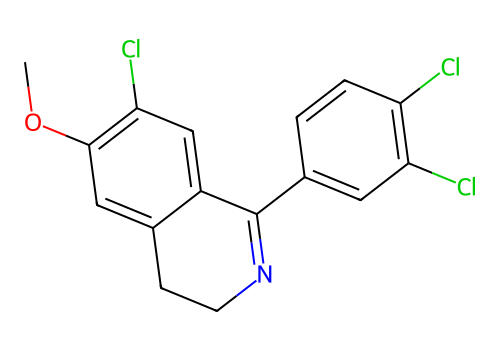

In [8]:
example_row = kiba_df.iloc[0]
example_drug_id = str(example_row["drug_id"])
example_smiles = example_row["smiles"]
example_graph = drug_graph_cache[example_drug_id]

print("Drug ID:", example_drug_id)
print("SMILES:", example_smiles)
print("Number of atoms:", example_graph.num_nodes)
print("Directed graph edges:", example_graph.edge_index.shape[1])
print("Node feature shape:", tuple(example_graph.x.shape))
print("Bond feature shape:", tuple(example_graph.edge_attr.shape))

molecule = Chem.MolFromSmiles(example_smiles)
display(Draw.MolToImage(molecule, size=(500, 350)))

## 8. Helper functions used by the three experiments

The functions below only organise repeated notebook steps.  
Each split still creates a **fresh GIN + CNN model** and is trained independently.

In [9]:
def create_loaders(train_df, validation_df, test_df):
    train_dataset = InteractionDataset(
        train_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    validation_dataset = InteractionDataset(
        validation_df,
        drug_graph_cache,
        protein_tensor_cache,
    )
    test_dataset = InteractionDataset(
        test_df,
        drug_graph_cache,
        protein_tensor_cache,
    )

    train_loader = DataLoader(
        train_dataset,
        batch_size=BATCH_SIZE,
        shuffle=True,
    )
    validation_loader = DataLoader(
        validation_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )
    test_loader = DataLoader(
        test_dataset,
        batch_size=BATCH_SIZE,
        shuffle=False,
    )

    return train_loader, validation_loader, test_loader


def print_split_summary(train_df, validation_df, test_df):
    summary = pd.DataFrame(
        {
            "partition": ["Train", "Validation", "Test"],
            "interactions": [
                len(train_df),
                len(validation_df),
                len(test_df),
            ],
            "unique_drugs": [
                train_df["drug_id"].nunique(),
                validation_df["drug_id"].nunique(),
                test_df["drug_id"].nunique(),
            ],
            "unique_targets": [
                train_df["target_id"].nunique(),
                validation_df["target_id"].nunique(),
                test_df["target_id"].nunique(),
            ],
        }
    )

    display(summary)


def plot_training_history(history, split_name):
    history_df = pd.DataFrame(history)

    plt.figure(figsize=(8, 5))
    plt.plot(
        history_df["epoch"],
        history_df["train_loss"],
        label="Training MSE",
    )
    plt.plot(
        history_df["epoch"],
        history_df["validation_loss"],
        label="Validation MSE",
    )
    plt.xlabel("Epoch")
    plt.ylabel("MSE")
    plt.title(f"KIBA GIN + CNN — {split_name}")
    plt.legend()
    plt.tight_layout()

    figure_path = (
        FIGURES_DIR
        / f"kiba_gin_cnn_{split_name}_training.png"
    )
    plt.savefig(figure_path, dpi=200, bbox_inches="tight")
    plt.show()

    return history_df


def run_gin_experiment(
    split_name,
    train_df,
    validation_df,
    test_df,
):
    print(f"Running split: {split_name}")
    print("-" * 60)

    train_loader, validation_loader, test_loader = create_loaders(
        train_df,
        validation_df,
        test_df,
    )

    model = GINCNN()
    trainable_parameters = count_trainable_parameters(model)

    print("Trainable parameters:", f"{trainable_parameters:,}")

    checkpoint_path = (
        CHECKPOINTS_DIR
        / f"kiba_gin_cnn_{split_name}.pt"
    )

    training_result = fit_model(
        model=model,
        train_loader=train_loader,
        validation_loader=validation_loader,
        device=device,
        checkpoint_path=checkpoint_path,
        max_epochs=MAX_EPOCHS,
        learning_rate=LEARNING_RATE,
    )

    history_df = plot_training_history(
        training_result["history"],
        split_name,
    )

    test_result = evaluate_model(
        model=model,
        data_loader=test_loader,
        device=device,
    )

    metrics = test_result["metrics"]

    predictions_df = test_df.copy()
    predictions_df["true_affinity"] = test_result["y_true"]
    predictions_df["predicted_affinity"] = test_result["y_pred"]
    predictions_df["prediction_error"] = (
        predictions_df["predicted_affinity"]
        - predictions_df["true_affinity"]
    )

    prediction_path = (
        PREDICTIONS_DIR
        / f"kiba_gin_cnn_{split_name}.csv"
    )

    save_predictions_csv(
        predictions_df,
        prediction_path,
    )

    result_row = {
        "dataset": "KIBA",
        "model": "GIN + CNN",
        "split": split_name,
        "best_epoch": training_result["best_epoch"],
        "completed_epochs": training_result["completed_epochs"],
        "best_validation_mse": training_result[
            "best_validation_mse"
        ],
        "test_mse": metrics["mse"],
        "test_rmse": metrics["rmse"],
        "test_mae": metrics["mae"],
        "ci": metrics["ci"],
        "pearson": metrics["pearson"],
        "trainable_parameters": trainable_parameters,
    }

    print()
    print("Best epoch:", result_row["best_epoch"])
    print(
        "Best validation MSE:",
        f'{result_row["best_validation_mse"]:.4f}',
    )
    print("Test MSE:", f'{result_row["test_mse"]:.4f}')
    print("Test RMSE:", f'{result_row["test_rmse"]:.4f}')
    print("Test MAE:", f'{result_row["test_mae"]:.4f}')
    print("Concordance index:", f'{result_row["ci"]:.4f}')
    print("Pearson correlation:", f'{result_row["pearson"]:.4f}')

    return {
        "model": model,
        "result": result_row,
        "history": history_df,
        "predictions": predictions_df,
        "checkpoint_path": checkpoint_path,
        "prediction_path": prediction_path,
    }

# Part B — Random split experiment

In the random split, interaction pairs are divided randomly into training, validation, and test sets.  
A drug or protein may therefore appear in more than one partition.

This setting measures performance when the model is evaluated on unseen **interaction pairs**, but not necessarily unseen drugs or proteins.

## 9. Create the random split

In [10]:
random_train_df, random_validation_df, random_test_df = random_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    random_train_df,
    random_validation_df,
    random_test_df,
)

random_drug_overlap = (
    set(random_train_df["drug_id"])
    & set(random_test_df["drug_id"])
)

random_target_overlap = (
    set(random_train_df["target_id"])
    & set(random_test_df["target_id"])
)

print(
    "Train-test drug overlap:",
    len(random_drug_overlap),
)
print(
    "Train-test target overlap:",
    len(random_target_overlap),
)

,partition,interactions,unique_drugs,unique_targets
0,Train,94603,2111,229
1,Validation,11825,1868,225
2,Test,11826,1877,221


Train-test drug overlap: 1877
Train-test target overlap: 221


## 10. Train and evaluate GIN + CNN on the random split

Running split: random
------------------------------------------------------------
Trainable parameters: 433,665
Epoch 001 | Train MSE: 2.5560 | Validation MSE: 0.6026
Epoch 002 | Train MSE: 1.7725 | Validation MSE: 0.9504
Epoch 003 | Train MSE: 1.4211 | Validation MSE: 0.8077
Epoch 004 | Train MSE: 1.0816 | Validation MSE: 0.5873
Epoch 005 | Train MSE: 0.9819 | Validation MSE: 0.5476
Epoch 006 | Train MSE: 0.9080 | Validation MSE: 0.5531
Epoch 007 | Train MSE: 0.8467 | Validation MSE: 0.5412
Epoch 008 | Train MSE: 0.7985 | Validation MSE: 0.5402
Epoch 009 | Train MSE: 0.7530 | Validation MSE: 0.5348
Epoch 010 | Train MSE: 0.7054 | Validation MSE: 0.5067
Epoch 011 | Train MSE: 0.6669 | Validation MSE: 0.5191
Epoch 012 | Train MSE: 0.6191 | Validation MSE: 0.5602
Epoch 013 | Train MSE: 0.5858 | Validation MSE: 0.4645
Epoch 014 | Train MSE: 0.5595 | Validation MSE: 0.5234
Epoch 015 | Train MSE: 0.5359 | Validation MSE: 0.4170
Epoch 016 | Train MSE: 0.5145 | Validation MSE: 0.4278
Epoch 0

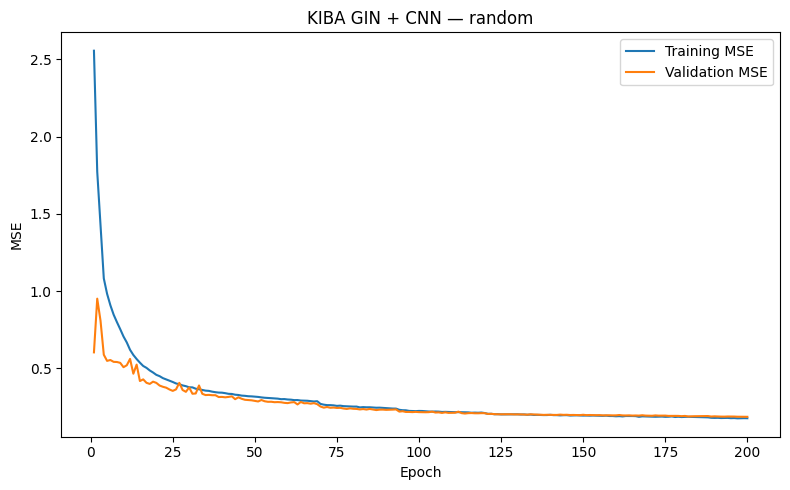


Best epoch: 200
Best validation MSE: 0.1853
Test MSE: 0.2010
Test RMSE: 0.4484
Test MAE: 0.2701
Concordance index: 0.8550
Pearson correlation: 0.8435


In [11]:
random_result = run_gin_experiment(
    split_name="random",
    train_df=random_train_df,
    validation_df=random_validation_df,
    test_df=random_test_df,
)

## 11. Inspect random-split predictions

In [12]:
display(
    random_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1966722,P35968,11.200000,11.501887,0.301888
1,CHEMBL1970142,P31749,11.200000,11.206940,0.006940
2,CHEMBL1986139,Q05397,11.900001,11.743264,-0.156736
3,CHEMBL1989043,P07333,11.700000,11.723716,0.023716
4,CHEMBL2001920,Q9Y6M4,11.300000,11.432935,0.132935
5,CHEMBL1969126,P53778,11.300000,11.340429,0.040429
6,CHEMBL1958401,P16591,11.900001,11.967395,0.067394
7,CHEMBL1997129,P49137,11.999998,13.946943,1.946945
8,CHEMBL1976420,O43781,11.300000,11.581025,0.281025
9,CHEMBL75773,Q04759,11.020819,11.466788,0.445970


# Part C — Cold-drug experiment

In the cold-drug split, drugs are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen drugs**, while protein targets may have been observed during training. This provides a more demanding assessment of generalisation to new compounds.

## 12. Create and verify the cold-drug split

In [13]:
cold_drug_train_df, cold_drug_validation_df, cold_drug_test_df = cold_drug_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
)

cold_drug_is_valid = check_cold_split(
    cold_drug_train_df,
    cold_drug_validation_df,
    cold_drug_test_df,
    column="drug_id",
)

print("No drug overlap:", cold_drug_is_valid)

assert cold_drug_is_valid, "Cold-drug split contains overlapping drugs."

,partition,interactions,unique_drugs,unique_targets
0,Train,94613,1688,229
1,Validation,11479,211,226
2,Test,12162,212,219


No drug overlap: True


## 13. Train and evaluate GIN + CNN on the cold-drug split

Running split: cold_drug
------------------------------------------------------------
Trainable parameters: 433,665
Epoch 001 | Train MSE: 2.6416 | Validation MSE: 0.9889
Epoch 002 | Train MSE: 1.8613 | Validation MSE: 0.9878
Epoch 003 | Train MSE: 1.5154 | Validation MSE: 0.6131
Epoch 004 | Train MSE: 1.1081 | Validation MSE: 0.6491
Epoch 005 | Train MSE: 0.9673 | Validation MSE: 0.6570
Epoch 006 | Train MSE: 0.8987 | Validation MSE: 0.5591
Epoch 007 | Train MSE: 0.8332 | Validation MSE: 0.5805
Epoch 008 | Train MSE: 0.7777 | Validation MSE: 0.6186
Epoch 009 | Train MSE: 0.7253 | Validation MSE: 0.5426
Epoch 010 | Train MSE: 0.6767 | Validation MSE: 0.5133
Epoch 011 | Train MSE: 0.6401 | Validation MSE: 0.6086
Epoch 012 | Train MSE: 0.6055 | Validation MSE: 0.5276
Epoch 013 | Train MSE: 0.5717 | Validation MSE: 0.5587
Epoch 014 | Train MSE: 0.5480 | Validation MSE: 0.4976
Epoch 015 | Train MSE: 0.5236 | Validation MSE: 0.5155
Epoch 016 | Train MSE: 0.5042 | Validation MSE: 0.5434
Epoc

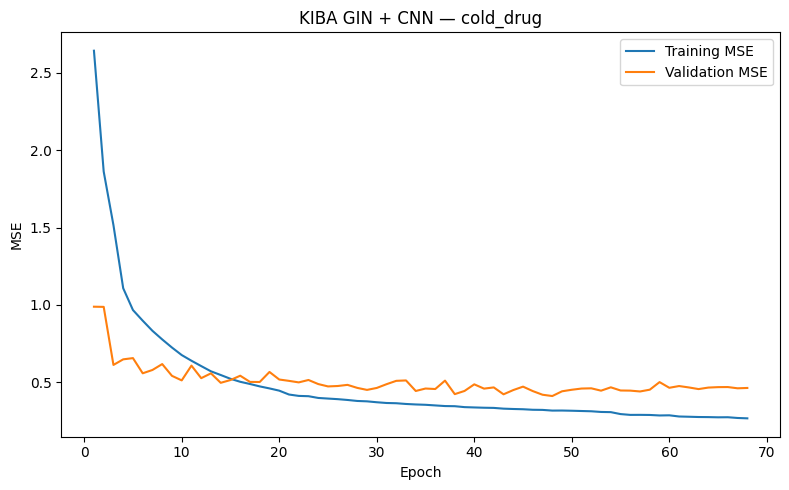


Best epoch: 48
Best validation MSE: 0.4122
Test MSE: 0.3823
Test RMSE: 0.6183
Test MAE: 0.4015
Concordance index: 0.7511
Pearson correlation: 0.6619


In [14]:
cold_drug_result = run_gin_experiment(
    split_name="cold_drug",
    train_df=cold_drug_train_df,
    validation_df=cold_drug_validation_df,
    test_df=cold_drug_test_df,
)

## 14. Inspect cold-drug predictions

In [15]:
display(
    cold_drug_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1788116,O00141,11.100000,11.165983,0.065983
1,CHEMBL1788116,O14757,11.100000,11.317645,0.217645
2,CHEMBL1788116,O14920,11.100000,11.459873,0.359873
3,CHEMBL1788116,O15530,11.100000,11.521221,0.421221
4,CHEMBL1788116,O75116,11.100000,11.132503,0.032502
5,CHEMBL1788116,O75582,11.100000,11.754083,0.654082
6,CHEMBL1788116,P00533,11.100000,11.801704,0.701704
7,CHEMBL1788116,P04049,12.020819,11.804738,-0.216081
8,CHEMBL1788116,P12931,12.058607,11.840322,-0.218286
9,CHEMBL1788116,P17252,11.100000,10.818394,-0.281607


# Part D — Cold-target experiment

In the cold-target split, protein targets are separated between training, validation, and test partitions.

The model is therefore evaluated on **unseen protein targets**, while drugs may have been observed during training.

## 15. Create and verify the cold-target split

In [16]:
cold_target_train_df, cold_target_validation_df, cold_target_test_df = cold_target_split(
    kiba_df,
    train_ratio=TRAIN_RATIO,
    validation_ratio=VALIDATION_RATIO,
    test_ratio=TEST_RATIO,
    seed=RANDOM_SEED,
)

print_split_summary(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
)

cold_target_is_valid = check_cold_split(
    cold_target_train_df,
    cold_target_validation_df,
    cold_target_test_df,
    column="target_id",
)

print("No target overlap:", cold_target_is_valid)

assert cold_target_is_valid, "Cold-target split contains overlapping targets."

,partition,interactions,unique_drugs,unique_targets
0,Train,94106,2111,183
1,Validation,11870,1606,22
2,Test,12278,1671,24


No target overlap: True


## 16. Train and evaluate GIN + CNN on the cold-target split

Running split: cold_target
------------------------------------------------------------
Trainable parameters: 433,665
Epoch 001 | Train MSE: 2.8754 | Validation MSE: 3.1650
Epoch 002 | Train MSE: 1.9205 | Validation MSE: 0.8298
Epoch 003 | Train MSE: 1.5540 | Validation MSE: 0.6445
Epoch 004 | Train MSE: 1.1442 | Validation MSE: 0.6034
Epoch 005 | Train MSE: 1.0324 | Validation MSE: 0.6180
Epoch 006 | Train MSE: 0.9463 | Validation MSE: 0.5780
Epoch 007 | Train MSE: 0.8814 | Validation MSE: 0.6178
Epoch 008 | Train MSE: 0.8156 | Validation MSE: 0.5966
Epoch 009 | Train MSE: 0.7748 | Validation MSE: 0.6442
Epoch 010 | Train MSE: 0.7324 | Validation MSE: 0.5677
Epoch 011 | Train MSE: 0.6834 | Validation MSE: 0.5748
Epoch 012 | Train MSE: 0.6457 | Validation MSE: 0.5970
Epoch 013 | Train MSE: 0.6203 | Validation MSE: 0.5484
Epoch 014 | Train MSE: 0.5938 | Validation MSE: 0.5455
Epoch 015 | Train MSE: 0.5647 | Validation MSE: 0.5447
Epoch 016 | Train MSE: 0.5443 | Validation MSE: 0.5379
Ep

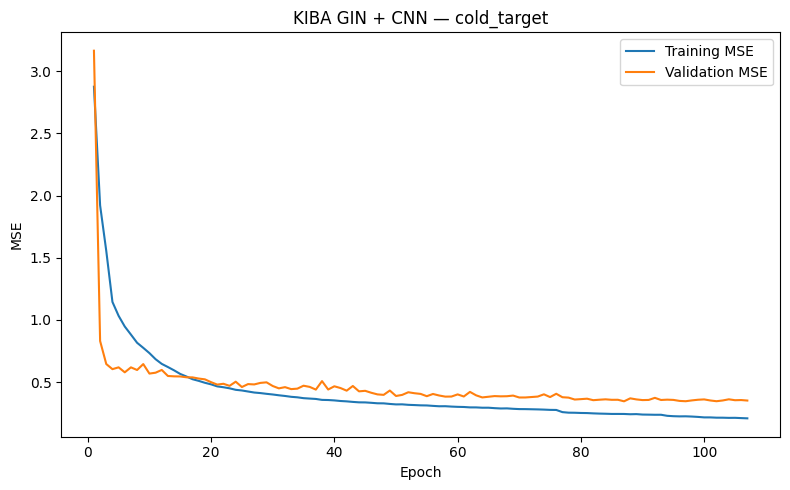


Best epoch: 87
Best validation MSE: 0.3447
Test MSE: 0.4070
Test RMSE: 0.6380
Test MAE: 0.4409
Concordance index: 0.7210
Pearson correlation: 0.6686


In [17]:
cold_target_result = run_gin_experiment(
    split_name="cold_target",
    train_df=cold_target_train_df,
    validation_df=cold_target_validation_df,
    test_df=cold_target_test_df,
)

## 17. Inspect cold-target predictions

In [18]:
display(
    cold_target_result["predictions"][
        [
            "drug_id",
            "target_id",
            "true_affinity",
            "predicted_affinity",
            "prediction_error",
        ]
    ].head(10)
)

,drug_id,target_id,true_affinity,predicted_affinity,prediction_error
0,CHEMBL1087421,P07333,11.100000,11.177073,0.077072
1,CHEMBL1087421,P53779,12.999993,11.172749,-1.827245
2,CHEMBL1088633,P07333,11.100000,10.981749,-0.118252
3,CHEMBL1088633,P53779,12.850003,10.940063,-1.909940
4,CHEMBL1090360,O14757,12.116100,12.079353,-0.036747
5,CHEMBL1090360,O15264,12.116100,12.024708,-0.091393
6,CHEMBL1090360,P06493,12.116100,11.713976,-0.402124
7,CHEMBL1090360,P07333,12.213943,12.530835,0.316892
8,CHEMBL1090360,P08922,11.800000,11.974518,0.174518
9,CHEMBL1090360,P16591,11.900001,12.100349,0.200349


# Part E — GIN + CNN results summary

The three experiments are now combined into one table.  
This file is the main output used later by the model-comparison notebook.

## 18. Combine and save the metrics

In [19]:
gin_results_df = pd.DataFrame(
    [
        random_result["result"],
        cold_drug_result["result"],
        cold_target_result["result"],
    ]
)

metrics_path = METRICS_DIR / "kiba_gin_cnn.csv"
gin_results_df.to_csv(metrics_path, index=False)

display(gin_results_df.round(4))

print("Metrics saved to:", metrics_path)

,dataset,model,split,best_epoch,completed_epochs,best_validation_mse,test_mse,test_rmse,test_mae,ci,pearson,trainable_parameters
0,KIBA,GIN + CNN,random,200,200,0.1853,0.2010,0.4484,0.2701,0.8550,0.8435,433665
1,KIBA,GIN + CNN,cold_drug,48,68,0.4122,0.3823,0.6183,0.4015,0.7511,0.6619,433665
2,KIBA,GIN + CNN,cold_target,87,107,0.3447,0.4070,0.6380,0.4409,0.7210,0.6686,433665


Metrics saved to: /content/final-msc-dissertation-drug-repurposing/results/metrics/kiba_gin_cnn.csv


## 19. Compare test RMSE across the three splits

Lower RMSE indicates better affinity prediction.
The cold-start results should be interpreted separately from the random split because they represent more difficult generalisation settings.

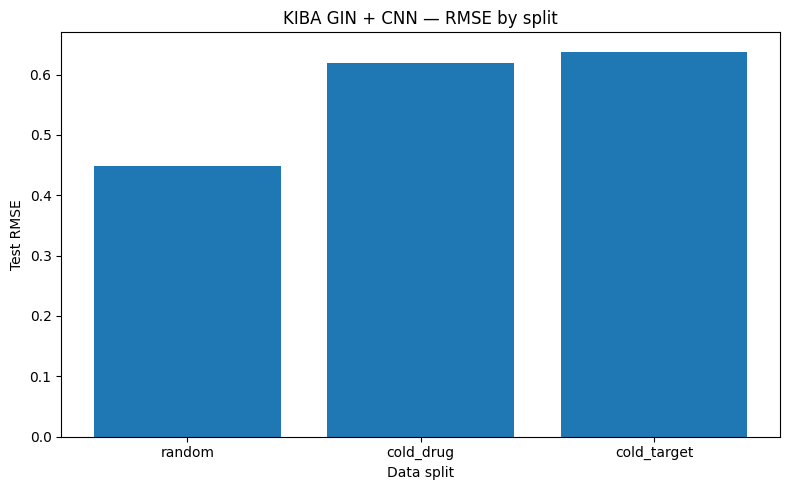

Comparison figure saved to: /content/final-msc-dissertation-drug-repurposing/results/figures/kiba_gin_cnn_split_comparison.png


In [20]:
plt.figure(figsize=(8, 5))
plt.bar(
    gin_results_df["split"],
    gin_results_df["test_rmse"],
)
plt.xlabel("Data split")
plt.ylabel("Test RMSE")
plt.title("KIBA GIN + CNN — RMSE by split")
plt.tight_layout()

comparison_figure_path = (
    FIGURES_DIR
    / "kiba_gin_cnn_split_comparison.png"
)

plt.savefig(
    comparison_figure_path,
    dpi=200,
    bbox_inches="tight",
)
plt.show()

print("Comparison figure saved to:", comparison_figure_path)

## 20. Final experiment summary

In [21]:
summary_columns = [
    "split",
    "best_epoch",
    "best_validation_mse",
    "test_rmse",
    "test_mae",
    "ci",
    "pearson",
]

final_summary = (
    gin_results_df[summary_columns]
    .sort_values("test_rmse")
    .reset_index(drop=True)
)

display(final_summary.round(4))

best_split = final_summary.iloc[0]

print(
    "Lowest test RMSE:",
    best_split["split"],
    f'({best_split["test_rmse"]:.4f})',
)

print()
print("Saved outputs")
print("-" * 50)
print("Metrics:", metrics_path)
print("Random predictions:", random_result["prediction_path"])
print("Cold-drug predictions:", cold_drug_result["prediction_path"])
print("Cold-target predictions:", cold_target_result["prediction_path"])
print("Figures folder:", FIGURES_DIR)
print("Checkpoints folder:", CHECKPOINTS_DIR)

,split,best_epoch,best_validation_mse,test_rmse,test_mae,ci,pearson
0,random,200,0.1853,0.4484,0.2701,0.8550,0.8435
1,cold_drug,48,0.4122,0.6183,0.4015,0.7511,0.6619
2,cold_target,87,0.3447,0.6380,0.4409,0.7210,0.6686


Lowest test RMSE: random (0.4484)

Saved outputs
--------------------------------------------------
Metrics: /content/final-msc-dissertation-drug-repurposing/results/metrics/kiba_gin_cnn.csv
Random predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gin_cnn_random.csv
Cold-drug predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gin_cnn_cold_drug.csv
Cold-target predictions: /content/final-msc-dissertation-drug-repurposing/results/predictions/kiba_gin_cnn_cold_target.csv
Figures folder: /content/final-msc-dissertation-drug-repurposing/results/figures
Checkpoints folder: /content/final-msc-dissertation-drug-repurposing/results/checkpoints


### Notebook completion

This notebook has completed the **KIBA GIN + CNN** baseline under random, cold-drug, and cold-target evaluation.

The saved `kiba_gin_cnn.csv` file can later be combined with the corresponding GCN + CNN and GAT + CNN result files for the final baseline model comparison.